<a href="https://colab.research.google.com/github/yadavanshudstcims2025-cell/machine-learning-short-codes/blob/main/logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Logistic Regression: Breast Cancer Classification

**Goal:** Classify tumors as malignant or benign using logistic regression.

**Steps:**
1. Load the Breast Cancer Wisconsin dataset
2. Explore the data
3. Split into training and testing sets
4. Scale the features
5. Train a Logistic Regression model
6. Evaluate using accuracy, precision, recall, F1-score, and confusion matrix

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
data = load_breast_cancer(as_frame=True)

df = data.frame

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
df.shape
df.info()
df.isnull().sum()
df["target"].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

,count
target,
1,357
0,212


In [ ]:
The dataset contains 569 samples and 30 features.
The target variable has two classes: malignant and benign.

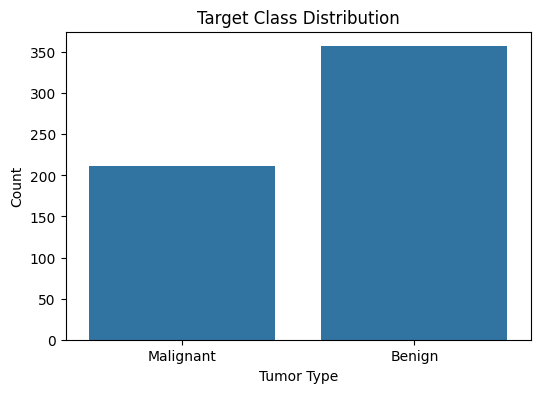

In [4]:
plt.figure(figsize=(6, 4))
sns.countplot(x=df["target"])
plt.xticks([0, 1], ["Malignant", "Benign"])
plt.title("Target Class Distribution")
plt.xlabel("Tumor Type")
plt.ylabel("Count")
plt.show()

In [5]:
X = df.drop(columns=["target"])
y = df["target"]

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (455, 30)
Testing data: (114, 30)


In [7]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [8]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [9]:
y_pred = model.predict(X_test_scaled)

In [11]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall:", round(recall, 3))
print("F1 Score:", round(f1, 3))
print(classification_report(y_test, y_pred))

Accuracy: 0.982
Precision: 0.986
Recall: 0.986
F1 Score: 0.986
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



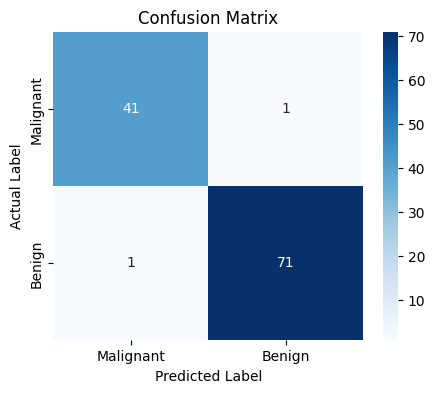

In [12]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()

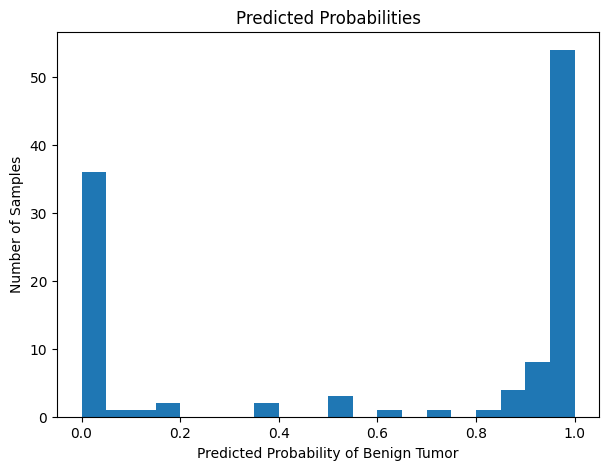

In [13]:
y_pred_prob = model.predict_proba(X_test_scaled)[:, 1]

plt.figure(figsize=(7, 5))
plt.hist(y_pred_prob, bins=20)
plt.xlabel("Predicted Probability of Benign Tumor")
plt.ylabel("Number of Samples")
plt.title("Predicted Probabilities")
plt.show()

In [ ]:
## Results

The Logistic Regression model was trained to classify breast tumors as malignant or benign.

The model was evaluated using accuracy, precision, recall, F1-score, and a confusion matrix.

Feature scaling was applied before training because logistic regression performs better when features are on similar scales.

## What I Learned

- Logistic regression is used for classification, not regression.
- It predicts the probability that an observation belongs to a class.
- Accuracy alone may not be enough, especially when classes are imbalanced.
- Precision tells us how many positive predictions were correct.
- Recall tells us how many actual positive cases were correctly identified.
- A confusion matrix shows true positives, true negatives, false positives, and false negatives.